# Titanic Data Analysis


## Import Library

In [269]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

## Load dataset

In [270]:
# Project paths
PROJECT_DIR = Path.cwd().parent

# NOTE: data/raw/train.csv must be the CORRUPTED file (train_corrupted.csv renamed)
RAW_DATA_PATH = PROJECT_DIR / "data" / "raw" / "train.csv"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
PROCESSED_DATA_PATH = PROJECT_DIR / "data" / "processed" / "train_clean.csv"   # different name, never overwrite raw

df = pd.read_csv(RAW_DATA_PATH)
df_original = df.copy()      # untouched backup, we only change df
df.head(10)
df.tail(10)
df.sample(10, random_state=1)

,Unnamed: 0,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Constant_Flag,Notes,Fare_Copy,Random_Token,Data_Source
267,267,656,0,2,"Hickman, Mr. Leonard Mark",male,24.0,45,0,S.O.C. 14879,73.5,NaN,NaN,TRAIN,NaN,73.5,931404,titanic_v2_export
291,291,133,0,3,"Robins, Mrs. Alexander A (Grace Charity Laury)",f,47.0,1,0,A/5.3337,14.5,NaN,S,TRAIN,NaN,14.5,929666,titanic_v2_export
480,480,431,1,1,"Bjornstrom-Steffansson, Mr. Mauritz Hakan",male,28.0,0,0,110564,26.55,C52,S,TRAIN,NaN,26.55,135252,titanic_v2_export
341,341,794,0,1,"Hoyt, Mr. William Fisher",M,NaN,0,0,PC 17600,30.6958,NaN,C,TRAIN,NaN,30.6958,747803,titanic_v2_export
320,320,473,1,2,"West, Mrs. Edwy Arthur (Ada Mary Worth)",female,33.0,1,2,C.A. 34651,27.75,NaN,s,TRAIN,NaN,27.75,771761,titanic_v2_export
35,35,659,0,2,"Eitemiller, Mr. George Floyd",male,23.0,0,0,29751,NaN,NaN,S,TRAIN,NaN,NaN,647866,titanic_v2_export
926,926,580,1,3,"Jussila, Mr. Eiriik",male,32.0,0,0,STON/O 2. 3101286,7.925,NaN,S,TRAIN,NaN,7.925,942647,titanic_v2_export
205,205,23,1,3,"McGowan, Miss. Anna ""Annie""",female,15.0,0,0,330923,8.0292,NaN,Q,TRAIN,NaN,8.0292,213097,titanic_v2_export
849,849,124,1,2,"Webber, Miss. Susan",NaN,32.5,0,0,27267,13.0,E101,s,TRAIN,NaN,13.0,939500,titanic_v2_export
754,754,77,0,3,"Staneff, Mr. Ivan",male,NaN,0,0,349208,NaN,NaN,S,TRAIN,NaN,NaN,569297,titanic_v2_export


## Understanding the dataset

In [271]:
print(df.shape)
df.dtypes

(931, 18)


Unnamed: 0         int64
PassengerId        int64
Survived             str
Pclass               str
Name                 str
Sex                  str
Age                  str
SibSp                str
Parch              int64
Ticket               str
Fare                 str
Cabin                str
Embarked             str
Constant_Flag        str
Notes            float64
Fare_Copy            str
Random_Token       int64
Data_Source          str
dtype: object

In [272]:
# Age, Fare, Pclass, Survived, SibSp should be numbers. If they show as text, the types are wrong.
df.describe()
df.describe(include=["object", "string"])

,Survived,Pclass,Name,Sex,Age,SibSp,Ticket,Fare,Cabin,Embarked,Constant_Flag,Fare_Copy,Data_Source
count,916,911,931,903,743,931,931,888,211,908,931,888,931
unique,13,12,900,14,117,13,689,276,141,17,1,276,1
top,0,3,"Rush, Mr. Alfred George John",male,24.0,0,347082,8.05,none,S,TRAIN,8.05,titanic_v2_export
freq,543,480,2,531,29,624,8,44,5,605,931,44,931


In [273]:
df.nunique().sort_values()
for col in ["Survived", "Pclass", "Sex", "SibSp", "Parch", "Embarked"]:
    print(col, df[col].value_counts(dropna=False).to_dict())
    
for col in ["Survived", "Pclass", "Sex", "SibSp", "Parch", "Embarked"]:
    print(df[col].unique())


Survived {'0': 543, '1': 333, nan: 15, 'N': 7, '-1': 5, 'Yes': 5, 'no': 4, 'False': 4, 'yes': 3, 'No': 3, 'True': 3, 'Y': 2, '2': 2, '5': 2}
Pclass {'3': 480, '1': 206, '2': 184, nan: 20, '3rd': 17, '1st': 9, '4': 4, '33': 4, 'First': 2, '2nd': 2, '7': 1, 'Second': 1, 'Third': 1}
Sex {'male': 531, 'female': 278, nan: 28, 'male ': 17, 'Male': 13, 'M': 9, 'f': 9, 'F': 9, ' male': 8, 'm': 7, 'MALE': 6, 'female ': 5, 'Female': 4, 'FEMALE': 4, ' female': 3}
SibSp {'0': 624, '1': 213, '2': 27, '4': 20, '3': 17, '8': 8, '5': 4, 'zero': 4, '-1': 3, '45': 3, '0.0': 3, 'one': 3, '1.0': 2}
Parch {0: 709, 1: 122, 2: 85, 5: 5, 3: 5, 4: 4, 6: 1}
Embarked {'S': 605, 'C': 160, 'Q': 74, nan: 23, 's': 18, 'southampton': 12, ' S': 11, 'Southampton': 7, '9': 4, 'c': 4, 'C ': 3, 'CHERBOURG': 2, 'X': 2, 'QUEENSTOWN': 2, ' Q': 1, 'Cherbourg': 1, 'q': 1, 'Z': 1}
<StringArray>
[    '0',     '1',     nan,    '-1',   'Yes',     'N',   'yes',    'no',
     'Y', 'False',    'No',     '2',  'True',     '5']
Length:

In [274]:
missing = pd.DataFrame({"count": df.isnull().sum(),"percent": (df.isnull().mean() * 100).round(1)})
missing.sort_values("percent", ascending=False)

,count,percent
Notes,931,100.00
Cabin,720,77.30
Age,188,20.20
Fare_Copy,43,4.60
Fare,43,4.60
Sex,28,3.00
Embarked,23,2.50
Pclass,20,2.10
Survived,15,1.60
Unnamed: 0,0,0.00


In [275]:
print(df.duplicated().sum())

if not df["PassengerId"].is_unique:
    print("duplicates exist:", df["PassengerId"].duplicated().sum())   

0
duplicates exist: 40


In [276]:
# verifying are these same columens 
df.nunique()                          
df["Fare"].equals(df["Fare_Copy"])    

True


## Data Cleaning

### 1.1 Inspect the messy columns first

In [277]:
for col in ["Survived", "Pclass", "Sex", "SibSp", "Embarked"]:
    print(col, df[col].value_counts(dropna=False).to_dict())
    print()

Survived {'0': 543, '1': 333, nan: 15, 'N': 7, '-1': 5, 'Yes': 5, 'no': 4, 'False': 4, 'yes': 3, 'No': 3, 'True': 3, 'Y': 2, '2': 2, '5': 2}

Pclass {'3': 480, '1': 206, '2': 184, nan: 20, '3rd': 17, '1st': 9, '4': 4, '33': 4, 'First': 2, '2nd': 2, '7': 1, 'Second': 1, 'Third': 1}

Sex {'male': 531, 'female': 278, nan: 28, 'male ': 17, 'Male': 13, 'M': 9, 'f': 9, 'F': 9, ' male': 8, 'm': 7, 'MALE': 6, 'female ': 5, 'Female': 4, 'FEMALE': 4, ' female': 3}

SibSp {'0': 624, '1': 213, '2': 27, '4': 20, '3': 17, '8': 8, '5': 4, 'zero': 4, '-1': 3, '45': 3, '0.0': 3, 'one': 3, '1.0': 2}

Embarked {'S': 605, 'C': 160, 'Q': 74, nan: 23, 's': 18, 'southampton': 12, ' S': 11, 'Southampton': 7, '9': 4, 'c': 4, 'C ': 3, 'CHERBOURG': 2, 'X': 2, 'QUEENSTOWN': 2, ' Q': 1, 'Cherbourg': 1, 'q': 1, 'Z': 1}



### 1.2 Drop junk columns

In [278]:
df = df.drop(columns=["Unnamed: 0", "Constant_Flag", "Notes", "Fare_Copy", "Random_Token", "Data_Source"])
df.shape

(931, 12)

### 1.3 Remove extra spaces and convert disguised nulls to NaN

In [279]:
# strip spaces from every text column
text_columns = df.select_dtypes(include=["object", "string"]).columns
for col in text_columns:
    df[col] = df[col].str.strip()

# words that mean "missing" -> real NaN
df = df.replace(["?", "N/A", "NA", "n/a", "unknown", "null", "none", "None", "-", ""], np.nan)
df.isnull().sum()

PassengerId      0
Survived        15
Pclass          20
Name             0
Sex             28
Age            200
SibSp            0
Parch            0
Ticket           0
Fare            43
Cabin          734
Embarked        23
dtype: int64

### 1.4 Standardize text (Sex, Embarked, Name, Ticket)

In [280]:
# Sex: take the first letter (m / f) and map it
df["Sex"] = df["Sex"].str.lower().str[0].map({"m": "male", "f": "female"})

# Embarked: first letter in capital (Southampton -> S)
df["Embarked"] = df["Embarked"].str.upper().str[0]

# Ticket: capital letters
df["Ticket"] = df["Ticket"].str.upper()

# Name: fix spacing, and fix names that are ALL CAPS or all lowercase
df["Name"] = df["Name"].str.replace(",", ", ").str.replace(".", ". ", regex=False)
df["Name"] = df["Name"].str.replace("  ", " ").str.strip()
for i in df.index:
    name = df.loc[i, "Name"]
    if pd.notnull(name) and (name.isupper() or name.islower()):
        df.loc[i, "Name"] = name.title()

print(df["Sex"].value_counts(dropna=False).to_dict())
print(df["Embarked"].value_counts(dropna=False).to_dict())

{'male': 591, 'female': 312, nan: 28}
{'S': 653, 'C': 170, 'Q': 78, nan: 23, '9': 4, 'X': 2, 'Z': 1}


### 1.5 Fix data types
Rule: **map the words first, then `pd.to_numeric` last.** If you convert first, the words turn into NaN and are lost.

In [281]:
# Age: words and units -> number text -> number
age_words = {"eighteen": "18", "five": "5", "thirty": "30", "thirty-five": "35",
             "twenty-five": "25", "twenty-two": "22"}
df["Age"] = df["Age"].str.lower().replace(age_words)
df["Age"] = df["Age"].str.replace(" years", "").str.replace("yrs", "")
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

# Fare: remove $ and use . as the decimal sign
df["Fare"] = df["Fare"].str.replace("$", "", regex=False).str.replace(",", ".")
df["Fare"] = pd.to_numeric(df["Fare"], errors="coerce")

# Pclass: 1st / First -> 1 ...
pclass_map = {"1st": "1", "first": "1", "2nd": "2", "second": "2", "3rd": "3", "third": "3"}
df["Pclass"] = df["Pclass"].str.lower().replace(pclass_map)
df["Pclass"] = pd.to_numeric(df["Pclass"], errors="coerce")

# Survived: Yes / No / True / False -> 1 / 0
survived_map = {"yes": "1", "y": "1", "true": "1", "no": "0", "n": "0", "false": "0"}
df["Survived"] = df["Survived"].str.lower().replace(survived_map)
df["Survived"] = pd.to_numeric(df["Survived"], errors="coerce")

# SibSp: words -> numbers
sibsp_map = {"zero": "0", "one": "1", "two": "2", "three": "3", "four": "4", "five": "5", "eight": "8"}
df["SibSp"] = df["SibSp"].str.lower().replace(sibsp_map)
df["SibSp"] = pd.to_numeric(df["SibSp"], errors="coerce")

df.dtypes

PassengerId      int64
Survived       float64
Pclass         float64
Name               str
Sex                str
Age            float64
SibSp          float64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

### 1.6 Incorrect values -> NaN
Now the columns are numbers, so range rules work. We don't delete these rows, we only blank the bad value and fill it in Step 2.

In [282]:
df.loc[(df["Age"] < 0) | (df["Age"] > 100), "Age"] = np.nan
df.loc[(df["Fare"] < 0) | (df["Fare"] > 600), "Fare"] = np.nan     
df.loc[~df["Pclass"].isin([1, 2, 3]), "Pclass"] = np.nan           
df.loc[~df["Survived"].isin([0, 1]), "Survived"] = np.nan
df.loc[(df["SibSp"] < 0) | (df["SibSp"] > 8), "SibSp"] = np.nan
df.loc[~df["Embarked"].isin(["S", "C", "Q"]), "Embarked"] = np.nan

### Verification

In [283]:
print(df["Pclass"].value_counts(dropna=False).to_dict())    # only 1, 2, 3 and NaN
print(df["Survived"].value_counts(dropna=False).to_dict())  # only 0, 1 and NaN
df.describe()

{3.0: 498, 1.0: 217, 2.0: 187, nan: 29}
{0.0: 561, 1.0: 346, nan: 24}


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,931.00,907.00,902.00,719.00,925.00,931.00,880.00
mean,446.97,0.38,2.31,29.52,0.53,0.38,31.81
std,257.21,0.49,0.83,14.48,1.12,0.80,49.44
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.00,0.00,2.00,20.00,0.00,0.00,7.90
50%,449.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,670.50,1.00,3.00,38.00,1.00,0.00,30.70
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33



## Handling Missing Values

### 2.1 Measure the problem

In [284]:
missing = pd.DataFrame({"count": df.isnull().sum(),"percent": (df.isnull().mean() * 100).round(1)})
missing.sort_values("percent", ascending=False)

,count,percent
Cabin,734,78.80
Age,212,22.80
Fare,51,5.50
Embarked,30,3.20
Pclass,29,3.10
Sex,28,3.00
Survived,24,2.60
SibSp,6,0.60
Name,0,0.00
PassengerId,0,0.00


### 2.2 Survived (target): drop the rows, never fill it

In [285]:
df = df.dropna(subset=["Survived"])
df = df.reset_index(drop=True)       # reset the index because we use loops with df.loc[i] below
df["Survived"] = df["Survived"].astype(int)
df.shape

(907, 12)

### 2.3 Sex: recover it from the title in Name (Mr, Mrs, Miss ...)

In [286]:
# Name looks like: "Braund, Mr. Owen Harris" -> take the text between "," and "."
df["Title"] = df["Name"].str.split(",").str[1].str.split(".").str[0].str.strip()
df["Title"].value_counts()

Title
Mr              528
Miss            183
Mrs             125
Master           42
Dr                7
Rev               6
Major             3
Col               2
Mlle              2
Sir               2
Don               1
Lady              1
Mme               1
Jonkheer          1
Ms                1
the Countess      1
Capt              1
Name: count, dtype: int64

In [287]:
male_titles = ["Mr", "Master", "Rev", "Don", "Major", "Col", "Capt", "Sir", "Jonkheer"]
female_titles = ["Mrs", "Miss", "Ms", "Mme", "Mlle", "Lady", "the Countess", "Dona"]

for i in df.index:
    if pd.isnull(df.loc[i, "Sex"]):
        title = df.loc[i, "Title"]
        if title in male_titles:
            df.loc[i, "Sex"] = "male"
        elif title in female_titles:
            df.loc[i, "Sex"] = "female"

# still missing (e.g. title "Dr")? use the most common value
df["Sex"] = df["Sex"].fillna(df["Sex"].mode()[0])
df["Sex"].isnull().sum()

np.int64(0)

### 2.4 Embarked and SibSp: fill with the most common value (mode)

In [288]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["SibSp"] = df["SibSp"].fillna(df["SibSp"].mode()[0])
df["SibSp"] = df["SibSp"].astype(int)
print(df["Embarked"].isnull().sum(), df["SibSp"].isnull().sum())

0 0


### 2.5 Fare and Pclass: use the class average and the "closest" idea
1. Find the average Fare of class 1, 2 and 3.
2. Pclass missing but Fare known -> pick the class whose average is **closest** to the fare.
3. Pclass still missing (Fare also missing) -> most common class.
4. Fare missing -> average Fare of the passenger's class.

In [289]:
# Step 1: average fare of each class
class_avg = df.groupby("Pclass")["Fare"].mean()
class_avg

Pclass
1.00   79.65
2.00   20.04
3.00   13.68
Name: Fare, dtype: float64

In [290]:
# If Pclass is missing AND Fare is given -> fill with closest class_avg
mask = df["Pclass"].isnull() & df["Fare"].notnull()
df.loc[mask, "Pclass"] = df.loc[mask, "Fare"].apply(lambda f: (class_avg - f).abs().idxmin())

# If both were missing (remaining NaNs in Pclass) -> fill with mode
df["Pclass"] = df["Pclass"].fillna(df["Pclass"].mode()[0]).astype(int)

# If Pclass is given (which is now every row!) -> fill missing Fare with class_avg
df["Fare"] = df["Fare"].fillna(df["Pclass"].map(class_avg))

print(df["Pclass"].isnull().sum(),"\t", df["Fare"].isnull().sum())

0 	 0


### 2.6 Age: average age of the Sex group

In [291]:
age_avg = df.groupby(["Sex"])["Age"].mean().round()
age_avg

Sex
female   27.00
male     31.00
Name: Age, dtype: float64

In [292]:
for i in df.index:
    if pd.isnull(df.loc[i, "Age"]):
        group = ( df.loc[i, "Sex"])
        df.loc[i, "Age"] = age_avg[group]

df["Age"].isnull().sum()

np.int64(0)

#### Verification 
Not filling cabin because it is missing over 77% of the data that can't be filled but used as feature(variable)

In [293]:
print(df.shape)
print(df.isnull().sum())   
df.dtypes
df.describe()

(907, 13)
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          713
Embarked         0
Title            0
dtype: int64


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,907.00,907.00,907.00,907.00,907.00,907.00,907.00
mean,450.29,0.38,2.30,29.64,0.53,0.38,31.88
std,255.72,0.49,0.84,12.82,1.13,0.80,48.49
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,229.50,0.00,2.00,22.00,0.00,0.00,7.92
50%,454.00,0.00,3.00,30.00,0.00,0.00,14.45
75%,672.50,1.00,3.00,35.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


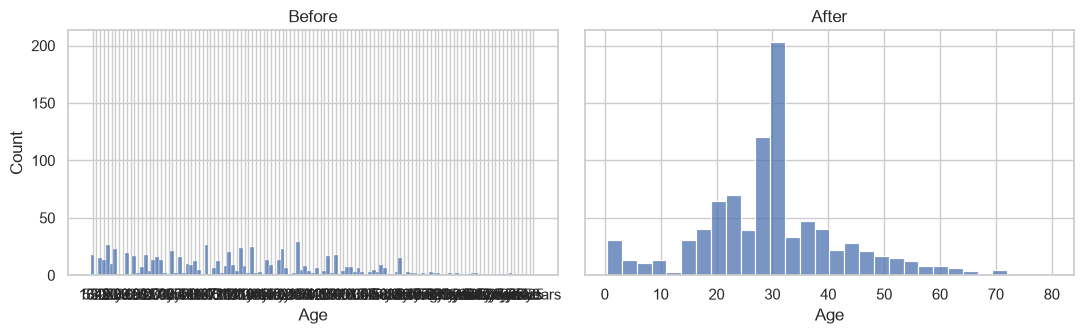

In [294]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
sns.histplot(df_original["Age"].dropna(), bins=30, ax=ax1)
sns.histplot(df["Age"], bins=30, ax=ax2)
ax1.set_title("Before")
ax2.set_title("After")
plt.tight_layout()   

### Save the cleaned data

In [295]:
df.to_csv(PROCESSED_DATA_PATH, index=False)
print("saved:", PROCESSED_DATA_PATH, df.shape)

saved: d:\Projects\Titanic\data\processed\train_clean.csv (907, 13)
